# CEO-Request Challenge

## 1. Sorun Tanımının Özeti

❓ **Olist kârını nasıl artırabilir?** ❓

### P&L Kuralları

#### Revenues  (Gelirler )
**Sales fees:** Olist, teslim edilen her order’ın ürün fiyatı üzerinden (freight hariç) **%10 pay** alır.  
**Subscription fees:** Olist, seller başına ayda **80 BRL** ücret alır.

#### Costs (Maliyetler)
Kötü review’lara (<= 3 stars) sahip orders için _tahmini_ **reputation costs**  

💡 Uzun vadede kötü customer experience iş açısından sonuçlara yol açar: düşük tekrar satın alma oranı, anında customer support maliyeti, refunds veya olumsuz word of mouth iletişimi. Her kötü review için parasal bir cost varsayımı yapıyoruz:

```python
# review_score: cost(BRL)
{'1 star': 100
'2 stars': 50
'3 stars': 40
'4 stars': 0
'5 stars': 0}
```

**IT costs:** Olist'in total cumulated IT Costs değeri, platforma şimdiye kadar katılmış toplam seller sayısının karekökü ile, şimdiye kadar satılmış toplam birikimli item sayısının karekökü oranında ölçeklenir.

$IT\_costs = \alpha * \sqrt{n\_sellers} + \beta * \sqrt{n\_items}$  

Olist'in data team’i bize bu scaling parameter’ları için şu değerleri verdi:
- $\alpha = 3157.27$
- $\beta = 978.23$

💡 Yönetilen seller sayısı da, sales transaction sayısı da IT systems için maliyetlidir.
💡 Ancak karekök kullanımı scale-effects’i gösterir: IT-system’ler büyüdükçe daha verimli olma eğilimindedir.
💡 Alpha > Beta olması, Olist’in çok item satan az sayıda seller ile çalıştığında, bunun tersi senaryoya göre daha düşük IT Cost’a sahip olduğu anlamına gelir.

1000 sellers ve toplam 100 items satışıyla toplam IT cost 109,624 BRL olur

100 sellers ve toplam 1000 items satışıyla toplam IT cost 62,507 BRL olur

Son olarak, IT department size marketplace’in kuruluşundan bu yana birikmiş IT costs toplamının 500,000 BRL olduğunu da iletti.

Şimdi, bu IT cost formülünü biraz daha iyi anlamak için bir simulation çalıştıralım. Kod üzerinde zaman harcamanıza gerek yok, sadece ortaya çıkan chart’lara bakın.

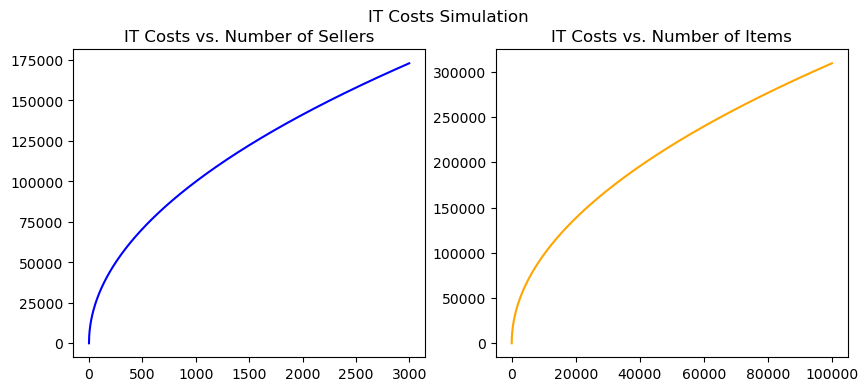

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

alpha = 3157.27
beta = 978.23

x_sellers = np.arange(3_000)
y_it_costs_sellers = alpha * x_sellers ** 0.5

x_items = np.arange(100_000)
y_it_costs_items = beta * x_items ** 0.5

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x_sellers, y_it_costs_sellers, label='IT costs per seller', color='blue')
plt.title('IT Costs vs. Number of Sellers')
plt.subplot(1, 2, 2)
plt.plot(x_items, y_it_costs_items, label='IT costs per item', color='orange')
plt.title('IT Costs vs. Number of Items')
plt.suptitle('IT Costs Simulation');

### Key Findings, so far

- `wait_time`, düşük review_score’ların arkasındaki en önemli faktördür.  
- `wait_time`, seller’ın `delay_to_carrier` süresi + `carrier_delivery_time` toplamından oluşur.  
- Carrier’ın delivery time’ı Olist’in doğrudan kontrolünde olmadığı için, bunu iyileştirmek hızlı kazanım sağlayacak bir öneri değildir.  
- Buna karşılık, daha iyi bir `seller` seçimi `delay_to_carrier` değerini olumlu şekilde etkileyebilir ve Olist üzerindeki kötü `review_scores` sayısını azaltabilir.  
- Kötü review’lardaki yorumlar, bazılarının seller’dan veya bizzat üründen kaynaklandığını göstermiştir.

💡 Aşağıdaki bölüm 2’deki guided seller analysis ile başlamanızı öneririz.

💪 Ancak bölüm 3 ile başka hipotezleri araştırmakta özgürsünüz.

## 2. Olist, performansları düşük satıcıları pazarından çıkarmalı mı? 🕵🏻
*(önerilen)*

Olist’in marketplace’inden en kötü seller’ları çıkarmanın etkisini analiz etmek için bir **what-if analysis** yapacağız.

👉 **Olist bu seller’ları en baştan hiç kabul etmemiş olsaydı ne olurdu?**  

*(Gerçekte, kimin iyi seller olduğunu önceden bilmek zordur, ancak bu yaklaşımla başlayıp daha sonra iterasyon yapacağız.)*


### 2.1 Veri Hazırlama

Her bir `seller_id` için, başlangıçtan itibaren kümülatif olarak hesaplayın:
- seller’ın getirdiği `revenues`
- seller’ın kötü review’larına bağlı `review_costs`
- ortaya çıkan `profits` (revenues - costs)

👉 İhtiyacınız olan DataFrame’i oluşturmak için adım adım bir strateji yazın.

⚠️ **Sıfırdan başlamayın, mevcut package’ınızı güncelleyin!** 😉

**Çözüm, notebook’a yeni kod yazmakta değil — `.py` dosyalarınızdaki kodu değiştirmektedir.**

`olist` package’ınız içindeki `Seller` class’ından başlayarak:

`get_training_data` method’unu düzenleyin; döndürdüğü DataFrame şu alanları içermeli:
- `revenues`: subscription + sales fees toplamı  
- `cost_of_reviews`: kötü review’lara bağlı toplam cost  
- `profits`: `revenues` - `cost_of_reviews`

`cost_of_reviews` için önce başka bir method’u değiştirmeniz gerekecek. Bununla ilgili olan method hangisi?

In [2]:
from olist.seller_updated import Seller
Seller().get_review_score().head()

,seller_id,share_of_five_stars,share_of_one_stars,review_score,cost_of_reviews
0,0015a82c2db000af6aaaf3ae2ecb0532,0.666667,0.333333,3.666667,100
1,001cca7ae9ae17fb1caed9dfb1094831,0.527919,0.121827,3.984772,3560
2,001e6ad469a905060d959994f1b41e4f,0.000000,1.000000,1.000000,100
3,002100f778ceb8431b7a1020ff7ab48f,0.519231,0.134615,3.903846,1110
4,003554e2dce176b5555353e4f3555ac8,1.000000,0.000000,5.000000,0


In [21]:
sellers = Seller().get_training_data()


In [22]:
negative_seller = (sellers['profits'] < 0).sum()
print(f"Number of sellers with negative profits: {negative_seller}")

Number of sellers with negative profits: 371


In [23]:
neg = sellers[sellers['profits'] < 0]

In [24]:
neg.head()

,seller_id,seller_city,seller_state,delay_to_carrier,wait_time,date_first_sale,date_last_sale,months_on_olist,n_orders,quantity,quantity_per_order,sales,share_of_five_stars,share_of_one_stars,review_score,cost_of_reviews,revenues,profits
4,51a04a8a6bdcb23deccc82b0b80742cf,braganca paulista,SP,3.353727,35.314861,2017-11-14 12:15:25,2017-11-14 12:15:25,0.0,1,1,1.000000,167.99,0.000000,1.000000,1.000000,100,16.799,-83.201
25,2a1348e9addc1af5aaa619b1a3679d6b,belo horizonte,MG,0.000000,27.203553,2017-01-14 01:30:17,2018-08-02 16:30:58,19.0,52,55,1.057692,2843.00,0.333333,0.352941,3.117647,2090,1804.300,-285.700
30,e9e446d01bd10a97a8ffcfc4a3a20cb2,sao paulo,SP,0.000000,5.304830,2018-06-06 02:53:58,2018-07-08 20:10:19,1.0,4,4,1.000000,60.05,0.500000,0.250000,3.500000,140,86.005,-53.995
45,8444e55c1f13cd5c179851e5ca5ebd00,congonhal,MG,0.000000,21.292399,2017-03-13 23:13:57,2018-07-06 02:55:16,16.0,99,109,1.101010,22873.21,0.363636,0.313131,3.262626,3620,3567.321,-52.679
57,b7ba853e9551f4558440881fd3e5c815,santo antonio da patrulha,RS,14.000833,34.955995,2016-10-06 15:56:40,2016-10-06 16:52:11,0.0,2,2,1.000000,376.80,0.000000,1.000000,1.000000,200,37.680,-162.320


In [25]:
print(f"Share of sellers with negative profits: {(sellers['profits'] < 0).mean():.1%}")

Share of sellers with negative profits: 12.5%


### 2.2 IT Maliyetleri Hariç Varsayım Analizi

👉 Gerçek analizi yapma zamanı. İlk olarak bunu IT costs **dahil etmeden** gerçekleştireceğiz.

Adımlarımız:  

1️⃣ Sellers verisini load edin ve profits değerine göre azalan şekilde sıralayın.

2️⃣ Cumulative değerleri hesaplayın:
   - Her satır için cumulative revenues hesaplayın.
   - Her satır için cumulative profits hesaplayın.
   - Her satır için cumulative items sold hesaplayın.

   Pandas ile cumulative sum nasıl hesaplanır, araştırın.

3️⃣ Sonuçlarınızı plot edin ve analiz edin. Pandas’ın `.plot()` method’unu kullanın.

4️⃣ Profits’e göre tutulması gereken optimum seller sayısını belirleyin. (İpucu: `np.argmax` araştırın). Bu kararın etkisi ne olurdu:
   - Net profit (IT costs dahil etmediğimiz için IT costs öncesi)?
   - Total revenues?
   - Seller sayısı?
   - Satılan item sayısı?

In [29]:
# SENİN KODUN BURAYA
sellers_sorted = sellers.sort_values(by='profits', ascending=False).reset_index(drop=True)

In [30]:
sellers_sorted['cum_revenues'] = sellers_sorted['revenues'].cumsum()
sellers_sorted['cum_profits'] = sellers_sorted['profits'].cumsum()
sellers_sorted['cum_quantity'] = sellers_sorted['quantity'].cumsum()

In [31]:
sellers_sorted.head(10)

,seller_id,seller_city,seller_state,delay_to_carrier,wait_time,date_first_sale,date_last_sale,months_on_olist,n_orders,quantity,...,sales,share_of_five_stars,share_of_one_stars,review_score,cost_of_reviews,revenues,profits,cum_revenues,cum_profits,cum_quantity
0,53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,0.0,13.374429,2017-08-28 18:44:58,2018-08-21 16:35:26,12.0,358,410,...,222776.05,0.561798,0.095506,4.132022,5170,23237.605,18067.605,23237.605,18067.605,410
1,7e93a43ef30c4f03f38b393420bc753a,barueri,SP,0.0,11.335141,2016-10-08 03:19:09,2018-07-14 21:25:19,21.0,336,340,...,176431.87,0.629851,0.101493,4.214925,4700,19323.187,14623.187,42560.792,32690.792,750
2,fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,0.0,13.341871,2017-01-07 20:55:10,2018-08-29 10:04:16,20.0,585,586,...,194042.03,0.676420,0.086059,4.339071,6510,21004.203,14494.203,63564.995,47184.995,1336
3,edb1ef5e36e0c8cd84eb3c9b003e486d,teresopolis,RJ,0.0,11.709806,2017-09-30 09:49:22,2018-08-20 19:30:10,11.0,166,175,...,79284.55,0.692771,0.066265,4.421687,1520,8808.455,7288.455,72373.450,54473.450,1511
4,46dc3b2cc0980fb8ec44634e21d2718e,rio de janeiro,RJ,0.0,11.800424,2016-10-06 15:44:00,2018-08-17 22:49:38,23.0,521,542,...,128111.19,0.629126,0.112621,4.194175,7500,14651.119,7151.119,87024.569,61624.569,2053
5,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,0.0,15.005261,2017-03-07 13:04:43,2018-08-24 19:55:21,18.0,1132,1156,...,229472.63,0.596975,0.106762,4.133452,17480,24387.263,6907.263,111411.832,68531.832,3209
6,ccc4bbb5f32a6ab2b7066a4130f114e3,curitiba,PR,0.0,15.853247,2017-01-07 14:00:13,2018-08-21 21:05:16,20.0,187,192,...,74004.62,0.650538,0.086022,4.284946,2220,9000.462,6780.462,120412.294,75312.294,3401
7,5dceca129747e92ff8ef7a997dc4f8ca,santa barbara d´oeste,SP,0.0,11.273755,2017-01-27 14:31:27,2018-06-26 00:33:18,17.0,325,346,...,112155.53,0.585670,0.140187,3.984424,6250,12575.553,6325.553,132987.847,81637.847,3747
8,17f51e7198701186712e53a39c564617,sao paulo,SP,0.0,22.761424,2017-02-04 13:05:50,2018-08-05 10:25:16,18.0,56,61,...,48019.00,0.660714,0.053571,4.339286,600,6241.900,5641.900,139229.747,87279.747,3808
9,e882b2a25a10b9c057cc49695f222c19,teresopolis,RJ,0.0,9.458803,2018-01-06 14:13:02,2018-08-18 16:10:04,7.0,57,58,...,51057.54,0.728814,0.016949,4.593220,240,5665.754,5425.754,144895.501,92705.501,3866


Text(0, 0.5, 'BRL')

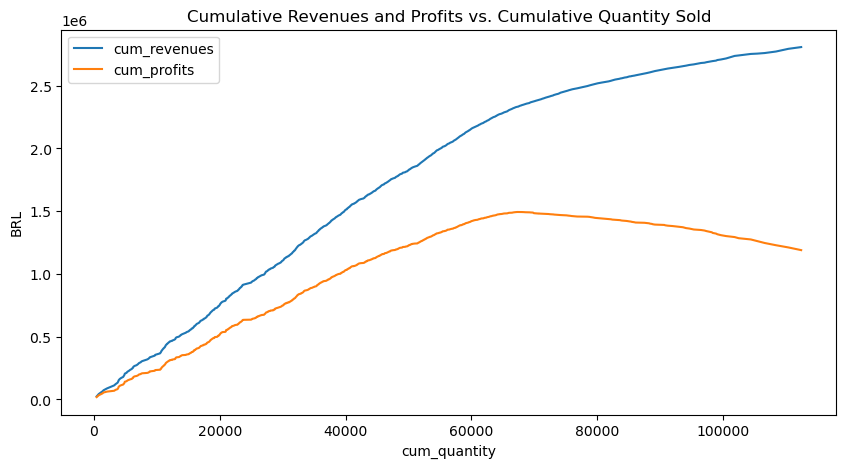

In [35]:
plt = sellers_sorted.plot(x='cum_quantity', y=['cum_revenues', 'cum_profits'], figsize=(10, 5), title='Cumulative Revenues and Profits vs. Cumulative Quantity Sold')
plt.set_ylabel('BRL')


<Axes: title={'center': 'Cumulative Revenues and Profits vs. Number of Sellers Kept'}, xlabel='Number of sellers kept (sorted by profit, best first)', ylabel='BRL'>

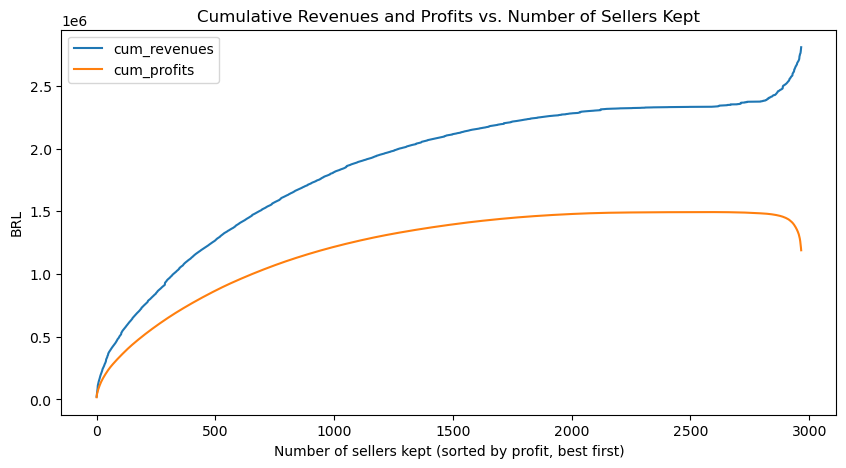

In [36]:
sellers_sorted.plot(
    y=['cum_revenues', 'cum_profits'],
    figsize=(10, 5),
    title='Cumulative Revenues and Profits vs. Number of Sellers Kept',
    xlabel='Number of sellers kept (sorted by profit, best first)',
    ylabel='BRL'
)

In [37]:
optimum_idx = np.argmax(sellers_sorted['cum_profits'])

n_total = len(sellers_sorted)
n_keep = optimum_idx + 1
n_remove = n_total - n_keep

print(n_total, n_keep, n_remove)

2967 2596 371


In [38]:
cols = ['cum_revenues', 'cum_profits', 'cum_quantity']

all_sellers = sellers_sorted[cols].iloc[-1]
optimum = sellers_sorted[cols].iloc[optimum_idx]


In [40]:
comparison = pd.DataFrame({'All Sellers': all_sellers, 'Optimum': optimum})
comparison['Difference'] = comparison['Optimum'] - comparison['All Sellers']
comparison['Change %'] = comparison['Difference'] / comparison['All Sellers'] * 100
comparison

,All Sellers,Optimum,Difference,Change %
cum_revenues,2807418.444,2333641.956,-473776.488,-16.875877
cum_profits,1189208.444,1493471.956,304263.512,25.585381
cum_quantity,112441.000,67503.000,-44938.000,-39.965849


### 2.3 IT maliyetleri ile varsayımsal analiz (İsteğe bağlı)

👉 Bu kez IT costs dahil edilerek gerçek analizi yapma zamanı.

Adımlarımız şunlar:  

1️⃣ İki parametreye göre IT costs hesaplayan bir function yazın: seller sayısı ve item sayısı. Temelde matematiksel formülü Python kullanarak yazmanız yeterli.

2️⃣ Sellers verisini load edin ve (IT costs öncesi) kârlarına göre azalan şekilde sıralayın.

3️⃣ Cumulative değerleri hesaplayın (önceki kodu yeniden kullanın):
   - Her satır için cumulative revenues hesaplayın.
   - Her satır için cumulative profits hesaplayın.
   - Her satır için toplam satılan item miktarının cumulative değerini hesaplayın.  

4️⃣ IT costs etkisini hesaplayın:
   - 1️⃣. adımda yazdığınız function’ı kullanarak her satır için cumulative IT cost ekleyin.
   - IT costs sonrası net profit’i hesaplayın.

5️⃣ Sonuçlarınızı plot edin ve analiz edin.

6️⃣ Bu kez IT costs sonrası kârları baz alarak tutulması gereken optimum seller sayısını belirleyin. Bu kararın etkisi ne olurdu:
   - IT costs sonrası net profit?
   - IT costs öncesi net profit?
   - IT costs?
   - Total revenues?
   - Seller sayısı?
   - Satılan item sayısı?

Analizinizde IT costs ne kadar önemliydi?


In [41]:
# SENİN KODUN BURAYA
def it_costs(n_sellers, n_items, alpha=3157.27, beta=978.23):
    return (alpha * n_sellers ** 0.5) + (beta * n_items ** 0.5)


In [44]:
print(it_costs(1000, 100))      # beklenen ≈ 109,624
print(it_costs(100, 1000))      # beklenen ≈ 62,507
print(it_costs(2967, 112441))

109623.9438811982
62507.04875506514
499999.31851932954


In [45]:
sellers_it = sellers_sorted.copy()

In [46]:
sellers_it['cum_revenues'] = sellers_it['revenues'].cumsum()
sellers_it['cum_profits'] = sellers_it['profits'].cumsum()
sellers_it['cum_quantity'] = sellers_it['quantity'].cumsum()

In [47]:
sellers_it.head()

,seller_id,seller_city,seller_state,delay_to_carrier,wait_time,date_first_sale,date_last_sale,months_on_olist,n_orders,quantity,...,sales,share_of_five_stars,share_of_one_stars,review_score,cost_of_reviews,revenues,profits,cum_revenues,cum_profits,cum_quantity
0,53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,0.0,13.374429,2017-08-28 18:44:58,2018-08-21 16:35:26,12.0,358,410,...,222776.05,0.561798,0.095506,4.132022,5170,23237.605,18067.605,23237.605,18067.605,410
1,7e93a43ef30c4f03f38b393420bc753a,barueri,SP,0.0,11.335141,2016-10-08 03:19:09,2018-07-14 21:25:19,21.0,336,340,...,176431.87,0.629851,0.101493,4.214925,4700,19323.187,14623.187,42560.792,32690.792,750
2,fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,0.0,13.341871,2017-01-07 20:55:10,2018-08-29 10:04:16,20.0,585,586,...,194042.03,0.676420,0.086059,4.339071,6510,21004.203,14494.203,63564.995,47184.995,1336
3,edb1ef5e36e0c8cd84eb3c9b003e486d,teresopolis,RJ,0.0,11.709806,2017-09-30 09:49:22,2018-08-20 19:30:10,11.0,166,175,...,79284.55,0.692771,0.066265,4.421687,1520,8808.455,7288.455,72373.450,54473.450,1511
4,46dc3b2cc0980fb8ec44634e21d2718e,rio de janeiro,RJ,0.0,11.800424,2016-10-06 15:44:00,2018-08-17 22:49:38,23.0,521,542,...,128111.19,0.629126,0.112621,4.194175,7500,14651.119,7151.119,87024.569,61624.569,2053


In [50]:
sellers_it['n_sellers'] = sellers_it.index + 1
sellers_it['cum_it_costs'] = it_costs(sellers_it['n_sellers'], sellers_it['cum_quantity'])
sellers_it['cum_profits_after_it'] = sellers_it['cum_profits'] - sellers_it['cum_it_costs']


In [51]:
sellers_it[['n_sellers', 'cum_quantity', 'cum_profits', 'cum_it_costs', 'cum_profits_after_it']].tail()

,n_sellers,cum_quantity,cum_profits,cum_it_costs,cum_profits_after_it
2962,2963,105443,1261524.075,489511.812301,772012.262699
2963,2964,106646,1245981.827,491347.711731,754634.115269
2964,2965,108421,1228400.669,494024.237152,734376.431848
2965,2966,110408,1210647.961,496991.389117,713656.571883
2966,2967,112441,1189208.444,499999.318519,689209.125481


In [52]:
optimum_idx_it = np.argmax(sellers_it['cum_profits_after_it'])

n_total_it = len(sellers_it)
n_keep_it = optimum_idx_it + 1
n_remove_it = n_total_it - n_keep_it

print(n_total_it, n_keep_it, n_remove_it)

2967 2117 850


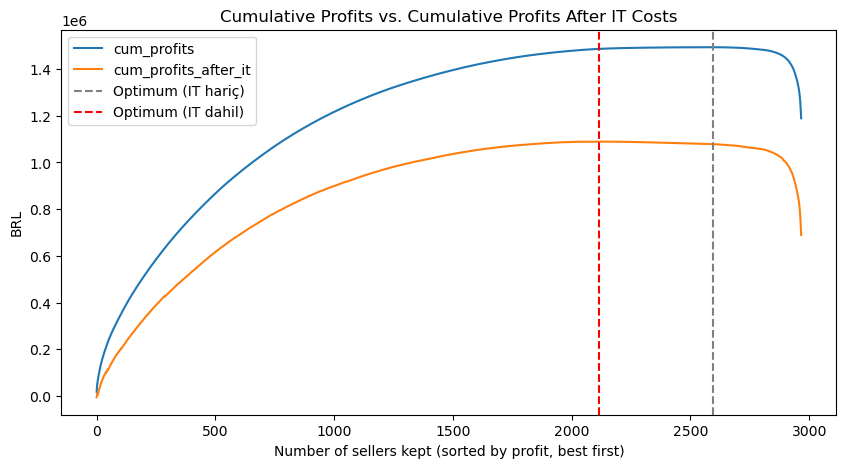

In [54]:
plt_it = sellers_it.plot(
    y=['cum_profits', 'cum_profits_after_it'],
    figsize=(10, 5),
    title='Cumulative Profits vs. Cumulative Profits After IT Costs',
    xlabel='Number of sellers kept (sorted by profit, best first)',
    ylabel='BRL'
)

plt_it.axvline(optimum_idx, color='gray', linestyle='--', label='Optimum (IT hariç)')
plt_it.axvline(optimum_idx_it, color='red', linestyle='--', label='Optimum (IT dahil)')
plt_it.legend()

In [55]:
cols_it = ['cum_profits_after_it', 'cum_profits', 'cum_it_costs', 'cum_revenues', 'cum_quantity']

all_sellers_it = sellers_it[cols_it].iloc[-1]
optimum_it = sellers_it[cols_it].iloc[optimum_idx_it]



In [59]:
comparison_it = pd.DataFrame({'All Sellers (IT dahil)': all_sellers_it, 'Optimum (IT dahil)': optimum_it})
comparison_it['Difference'] = comparison_it['Optimum (IT dahil)'] - comparison_it['All Sellers (IT dahil)']
comparison_it['Change %'] = comparison_it['Difference'] / comparison_it['All Sellers (IT dahil)'] * 100
comparison_it

,All Sellers (IT dahil),Optimum (IT dahil),Difference,Change %
cum_profits_after_it,6.892091e+05,1.089861e+06,400651.722757,58.132098
cum_profits,1.189208e+06,1.486365e+06,297156.809000,24.987782
cum_it_costs,4.999993e+05,3.965044e+05,-103494.913757,-20.699011
cum_revenues,2.807418e+06,2.304635e+06,-502783.191000,-17.909093
cum_quantity,1.124410e+05,6.596000e+04,-46481.000000,-41.338124


In [60]:
profit_at_grey = sellers_it['cum_profits_after_it'].iloc[optimum_idx]
profit_at_red  = sellers_it['cum_profits_after_it'].iloc[optimum_idx_it]
print(profit_at_red, profit_at_grey, profit_at_red - profit_at_grey)

1089860.8482372754 1078448.7716139692 11412.076623306144


## 4. Sonuç ve Öneri

### CEO'nun sorusu
Olist, kârını artırmak için kaç düşük performanslı seller'ı çıkarmalı?

### Kısa cevap
IT maliyetleri dahil edildiğinde kârı maksimize eden sayı **850 seller**'dır (toplamın %28.6'sı).
Bu, IT sonrası net kârı **689K BRL → 1.09M BRL** seviyesine çıkarır (**+401K BRL, +%58**).

### Senaryolar
| Senaryo | Çıkarılan | IT sonrası kâr | Kazanç | Gelir değişimi | Item değişimi |
|---|---|---|---|---|---|
| Mevcut | 0 | 689K | – | – | – |
| A: Maks. kâr | 850 | 1,090K | +401K (+%58.1) | −%17.9 | −%41.3 |
| B: Temkinli | 371 | 1,078K | +389K (+%56.5) | −%16.9 | −%40.0 |

### Temel bulgular
1. Seller'ların %12.5'i (371) IT öncesi bile **negatif kâr** üretiyor.
2. En zararlı seller'lar küçük değil, **yüksek hacimli** seller'lar: %12.5'lik grup, satılan item'ların %40'ını satıyor.
3. IT maliyetleri çıkarılması gereken sayıyı 371'den 850'ye çıkarıyor. Kazancın ~%26'sı (103.5K) IT tasarrufundan geliyor.
4. Kâr eğrisinin tepesi çok düz: B senaryosu, A'nın kazancının **%97'sini** 479 daha az seller çıkararak yakalıyor.

### Öneri
B senaryosuyla ilerlerdim zaten kazancın **%97'sini** yakalıyor ve de daha az seller çıkartılıyor bu da hacmi bir koruyor.

### Varsayımlar
- **Gelir:** Ürün fiyatının %10'u (freight hariç) + seller başına aylık 80 BRL.
  `months_on_olist` = (son satış − ilk satış) / 30 gün, yuvarlanmış. Tek ayda satış yapan
  seller'lar 0 ay sayılıyor, bu nedenle gelirleri olduğundan düşük tahmin ediliyor.
- **Satış tutarı:** `order_items` içindeki tüm kalemler (teslim durumu filtrelenmedi).
- **Review maliyeti (tahmini):** 1⭐ 100, 2⭐ 50, 3⭐ 40, 4–5⭐ 0 BRL.
  Birden fazla seller'lı siparişlerde maliyet her seller'a tam olarak yazıldı.
- **IT maliyeti:** α√n_sellers + β√n_items (α=3157.27, β=978.23).
  Model tüm seller'lar için 499,999 BRL hesaplayarak IT departmanının bildirdiği 500,000 BRL ile doğrulandı.
- **What-if varsayımı:** Çıkarılan seller'ların siparişleri tamamen kayboluyor, müşteriler başka
  seller'lara geçmiyor. Sıralama geçmiş veriye göre yapıldı (gerçekte hangi seller'ın kötü
  olacağını önceden bilmek zor).

### Sınırlamalar ve sonraki adımlar
- Review maliyetleri tahmini; farklı değerlerle duyarlılık analizi yapılmalı.
- Yüksek hacimli zararlı seller'ları çıkarmak yerine `delay_to_carrier` gibi metrikleri
  iyileştirmeye yönelik programlar denenebilir.
- Yeni seller'lar için "deneme süresi" sonrası değerlendirme yaklaşımı (bölüm 3) incelenebilir.

## 3. Diğer Yaklaşımları Araştırın 🕵️
*(isteğe bağlı)*

- Olist, en kötü performans gösteren ürünleri/kategorileri pazarından tamamen kaldırmalı mı?
- Olist, birkaç aylık balayı döneminden sonra, sadece sürekli olarak düşük performans gösteren satıcıları kaldırmalı mı?
- Olist, satıcılardan ürün listelerine belirli bilgileri eklemelerini zorunlu kılmalı mı?
- Olist, günün belirli saatlerinde müşterilerden satın alma onayı istemeli mi?
- Olist, gecikmeleri önlemek için belirli eyaletler arasındaki satıcı/müşteri çiftlerini kısıtlamalı mı?
- Olist, bazı maliyet varsayımları önerilerek yeni satıcılar kazanmalı mı?
- ...

## Sıra Sende!

🧺 Bu defteri düzenli tutun! 

🗣 📊 Bu `Communicate`  ünitesinin sonunda, en sevdiğiniz TA'ya görüşlerinizi sunacaksınız 💪